LAB of Information Systems and Analytics.

Students:

Dayana Amanzhol 908489

Aiday Karazhan 903774

# Customer Churn Prediction

## Business Context

Customer churn is when a customer cancels a subscription or leaves a service, one of the most costly problems in telecommunications. Acquiring a new customer costs five to ten times more than retaining an existing one, making proactive retention far more valuable than reactive recovery. A reliable churn model allows the company to identify at-risk customers before they leave and intervene with targeted offers: a contract upgrade incentive, a pricing adjustment, or a proactive support call.

## Project Objective

This project builds an end-to-end binary classification pipeline using the IBM Telco Customer Churn dataset (7,043 customers, 20 features), covering the full CRISP-DM cycle from data exploration through modeling, evaluation, and error analysis. Three models are trained and compared: Logistic Regression, Random Forest, and XGBoost, with ROC-AUC and recall as the primary metrics, reflecting the asymmetric cost of missing a churner versus sending an unnecessary retention offer.

## Phase 1: Setup

In [ ]:
#installing the libraries that are not pre-installed in Colab
!pip install xgboost imbalanced-learn -q

In [ ]:
# libraries for data manipulation
import numpy as np
import pandas as pd

# libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# machine learning: models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# machine learning: preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

# machine learning: evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve,
    f1_score
)

#handling class imbalance
from imblearn.over_sampling import SMOTE

# miscellaneous
import warnings
warnings.filterwarnings('ignore')  # suppress minor warnings for cleaner output

#plot style
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Telco Churn Project/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The dataset contains 7,043 customers and 21 columns covering demographics, account information, subscribed services, contract details, and a binary churn target. Before building any model, we need to understand the data thoroughly — its structure, distributions, missing values, class balance, and relationships between features. The goal of this section is not just to describe the data but to extract insights that will directly inform preprocessing and modeling decisions.

## Phase 2: Exploratory Data Analysis
We get a first look at the dataset before doing anything else. We check how many rows and columns we have, and what data type each column is stored as. This helps us spot potential issues early, such as numerical columns mistakenly loaded as text (object type).

In [ ]:
# first look at the dataset shape(number of rows and columns) and data type of each column
print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)

Shape: (7043, 21)

Column types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


The dataset contains 7,043 rows and 21 columns. Most columns are of type "object" (categorical text), while tenure, MonthlyCharges, and SeniorCitizen are numerical. Observations that are made from this:

1.   SeniorCitizen is stored as "int64" (0 and 1), but it is actually a binary
categorical variable meaning "is the customer a senior citizen or not". Keeping it as "int64" would cause it to be treated as a continuous number in statistical summaries and plots, which is misleading. We convert it to a readable 'Yes'/'No' string so it behaves consistently with the other binary columns (Partner, Dependents, etc.) throughout the EDA;
2.   TotalCharges appears as "object" instead of "float64", this is unexpected for a monetary value and signals a data quality issue that will be investigated in the next cell.

**Fixing SeniorCitizen Dtype**

In [ ]:
# Map 0 → 'No' and 1 → 'Yes' for consistency with other binary columns
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# Confirm the change
print("SeniorCitizen unique values:", df['SeniorCitizen'].unique())
print("dtype:", df['SeniorCitizen'].dtype)

SeniorCitizen unique values: ['No' 'Yes']
dtype: object


SeniorCitizen has been converted from integer (0/1) to a readable categorical format ('Yes'/'No'), consistent with all other binary columns in the dataset. This ensures it is treated correctly in visualizations and churn rate calculations.

**Missing Values and the TotalCharges Column.**
Now, we need to identify missing or malformed data before any analysis. A standard isnull() check is not enough here, because some missing values can be encoded as blank strings ' ' rather than NaN, which pandas does not count as missing by default. We need to catch both cases.

In [ ]:
# standard missing value check that counts NaN values per column
print("Missing values per column:")
print(df.isnull().sum())

# TotalCharges was loaded as text (object), meaning some values are blank strings
# we filter rows where TotalCharges is exactly a blank space ' '
# and inspect their tenure to understand why the value is missing
print("\nRows with blank TotalCharges:")
print(df[df['TotalCharges'] == ' '][['customerID', 'tenure', 'TotalCharges']])

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Rows with blank TotalCharges:
      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             
3331  7644-OMVMY       0             
3826  3213-VVOLG       0             
4380  2520-SGTTA       0             
5218  2923-ARZLG       0             
6670  4075-WKNIU       0             
6754  2775-SEFEE       0             


The standard missing value check returns zero nulls across all columns, which might suggest the data is clean. However, TotalCharges contains 11 rows with blank string values (' ') that pandas did not flag as missing. Inspecting those rows reveals that all 11 customers have tenure = 0, meaning they are brand new customers who have not yet been billed. This is not a data error but rather a logical gap. We will handle this in the next cell by **converting TotalCharges to numeric and filling these blanks with 0.**

In [ ]:
# convert TotalCharges from text to numeric
# errors='coerce' silently turns unparseable values into NaN instead of raising an error
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Fill the 11 NaN values with 0 — these are new customers with no charges yet
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Fixed! Summary statistics:")

# describe() gives count, mean, std, min, quartiles, max for numerical columns
# this helps spot outliers, skewed distributions, or implausible values
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()

Fixed! Summary statistics:


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


After fixing TotalCharges, the summary statistics reveal several useful patterns. Tenure ranges from 0 to 72 months, with a mean of ~32 months, suggesting a fairly spread customer base in terms of loyalty. MonthlyCharges range from ~18 to 119 dollars, with a mean of ~65 dollars, indicating meaningful variation that could correlate with churn. TotalCharges has a wide range (0 to ~8,684 dollars) and is largely determined by the combination of tenure and monthly charges, so it carries overlapping information with both, a multicollinearity concern we will revisit during modeling.

**Target Variable Distribution (Class Imbalance).** After, we have to understand how balanced the dataset is between churners and non-churners. This is the first and most critical step before choosing models and metrics. If the classes are imbalanced, accuracy becomes a misleading metric, a model that always predicts "No Churn" would still score ~73% accuracy while being completely useless for identifying customers at risk.

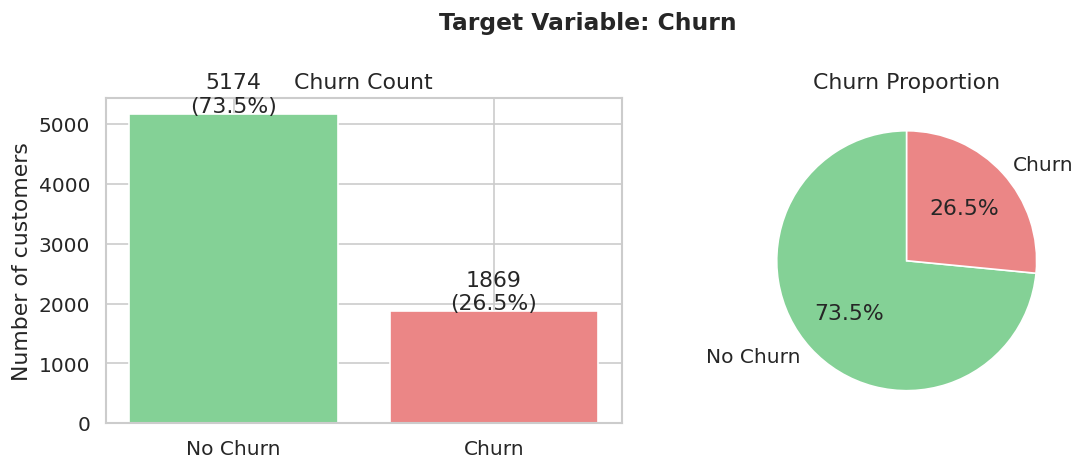


Key point: ~26% churn rate means the dataset is imbalanced.
This means accuracy alone is a misleading metric, we'll use ROC-AUC and F1 instead.


In [ ]:
# count absolute number of churners and non-churners
churn_counts = df['Churn'].value_counts()

# compute proportions (normalize=True gives fractions, × 100 gives percentages)
churn_pct = df['Churn'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# left plot: bar chart with count and percentage labels
axes[0].bar(['No Churn', 'Churn'], churn_counts.values,
            color=['#84d196', '#eb8686'], edgecolor='white')
axes[0].set_title('Churn Count')
axes[0].set_ylabel('Number of customers')

# annotate each bar with the absolute count and its percentage
for i, (v, p) in enumerate(zip(churn_counts.values, churn_pct.values)):
    axes[0].text(i, v + 30, f'{v}\n({p:.1f}%)', ha='center')

# right plot: pie chart for visual proportion comparison
axes[1].pie(churn_counts.values, labels=['No Churn', 'Churn'],
            colors=['#84d196', '#eb8686'], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Churn Proportion')

plt.suptitle('Target Variable: Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print a note on why this matters for metric selection
print("\nKey point: ~26% churn rate means the dataset is imbalanced.")
print("This means accuracy alone is a misleading metric, we'll use ROC-AUC and F1 instead.")

The dataset is imbalanced: 73.5% of customers did not churn, while only 26.5% did. This is typical for churn datasets in real-world settings. The imbalance has two important consequences for our analysis. First, accuracy is not a reliable metric, model that always predicts "No Churn" would achieve 73.5% accuracy without learning anything useful. Second, we need to address the imbalance during training, either by resampling (SMOTE) or by using class weights. We will use ROC-AUC, F1-score, and Precision-Recall AUC as our primary evaluation metrics throughout the project.

**Numerical Features and Churn.** Next, we visualize how the three numerical features (tenure, MonthlyCharges, TotalCharges) differ between churners and non-churners. We use two complementary chart types per feature:
  - Histogram: shows the full distribution shape and overlap between groups;
  - Boxplot: highlights median, spread, and outliers per group.

Together they give a complete picture of how each feature relates to churn.

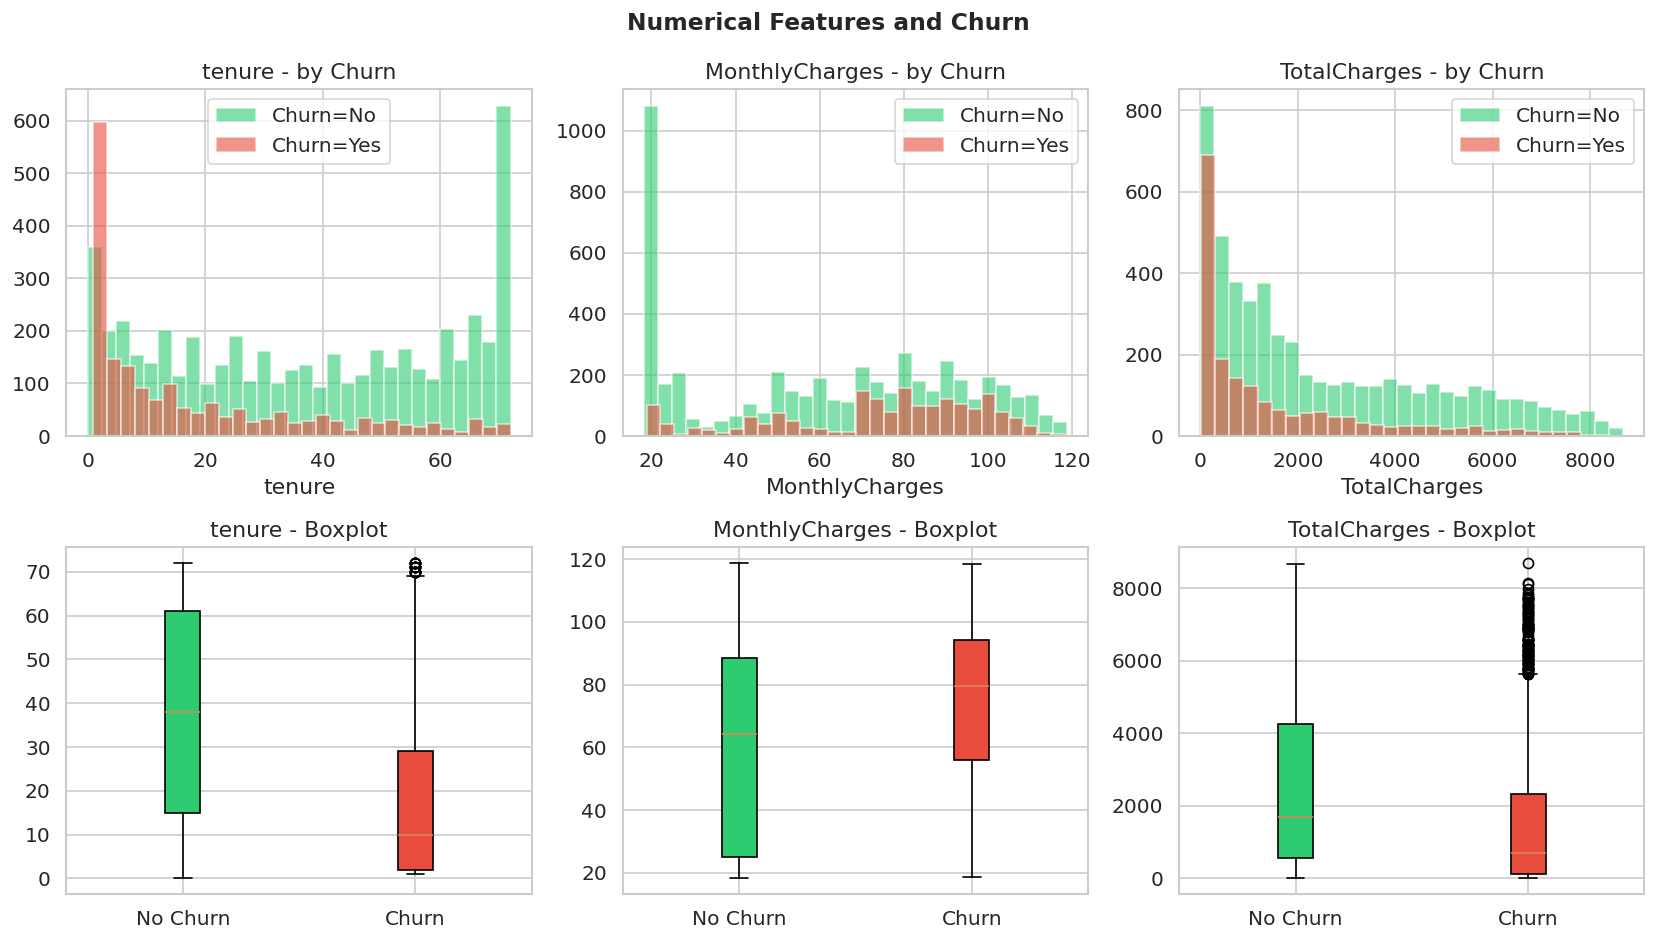

Observations:
  • Churners have shorter tenure → they leave early in their lifecycle
  • Churners pay higher monthly charges → price sensitivity is a likely factor
  • Total charges are lower for churners despite higher monthly rates (due to short tenure)


In [ ]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# create a 2-row, 3-column grid: top row = histograms, bottom row = boxplots
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, col in enumerate(num_cols):

    # top row: overlapping histograms split by churn status
    # alpha=0.6 makes bars semi-transparent so both distributions are visible
    for label, color in [('No', '#2ecc71'), ('Yes', '#e74c3c')]:
        axes[0, i].hist(df[df['Churn'] == label][col], bins=30,
                        alpha=0.6, color=color, label=f'Churn={label}', edgecolor='white')
    axes[0, i].set_title(f'{col} - by Churn')
    axes[0, i].set_xlabel(col)
    axes[0, i].legend()

    # bottom row: side-by-side boxplots
    # patch_artist=True allows us to fill the boxes with color
    data = [df[df['Churn'] == 'No'][col], df[df['Churn'] == 'Yes'][col]]
    bp = axes[1, i].boxplot(data, patch_artist=True)
    bp['boxes'][0].set_facecolor('#2ecc71')   # No churn = green
    bp['boxes'][1].set_facecolor('#e74c3c')   # Churn = red
    axes[1, i].set_xticklabels(['No Churn', 'Churn'])
    axes[1, i].set_title(f'{col} - Boxplot')

plt.suptitle('Numerical Features and Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observations:")
print("  • Churners have shorter tenure → they leave early in their lifecycle")
print("  • Churners pay higher monthly charges → price sensitivity is a likely factor")
print("  • Total charges are lower for churners despite higher monthly rates (due to short tenure)")

Three clear patterns emerge from the numerical features. **Tenure**: churners are heavily concentrated in the 0–20 month range, while loyal customers are spread across the full 0–72 month range. This suggests that the first year is the highest-risk period for losing a customer. **MonthlyCharges**: churners consistently pay more per month, their distribution skews right compared to non-churners. This points to price sensitivity as a contributing factor. **TotalCharges**: despite paying more monthly, churners have lower total charges overall because their tenure is so short. This also means TotalCharges is largely redundant with tenure and MonthlyCharges combined, a potential multicollinearity issue for linear models that we will address during preprocessing.

**Churn Rate per Categorical Feature.** Also, we understand which categories within each feature are associated with higher churn. Instead of just showing counts, we compute the CHURN RATE(percentage of customers who churned) within each category. This is more informative than raw counts because categories have different sizes.

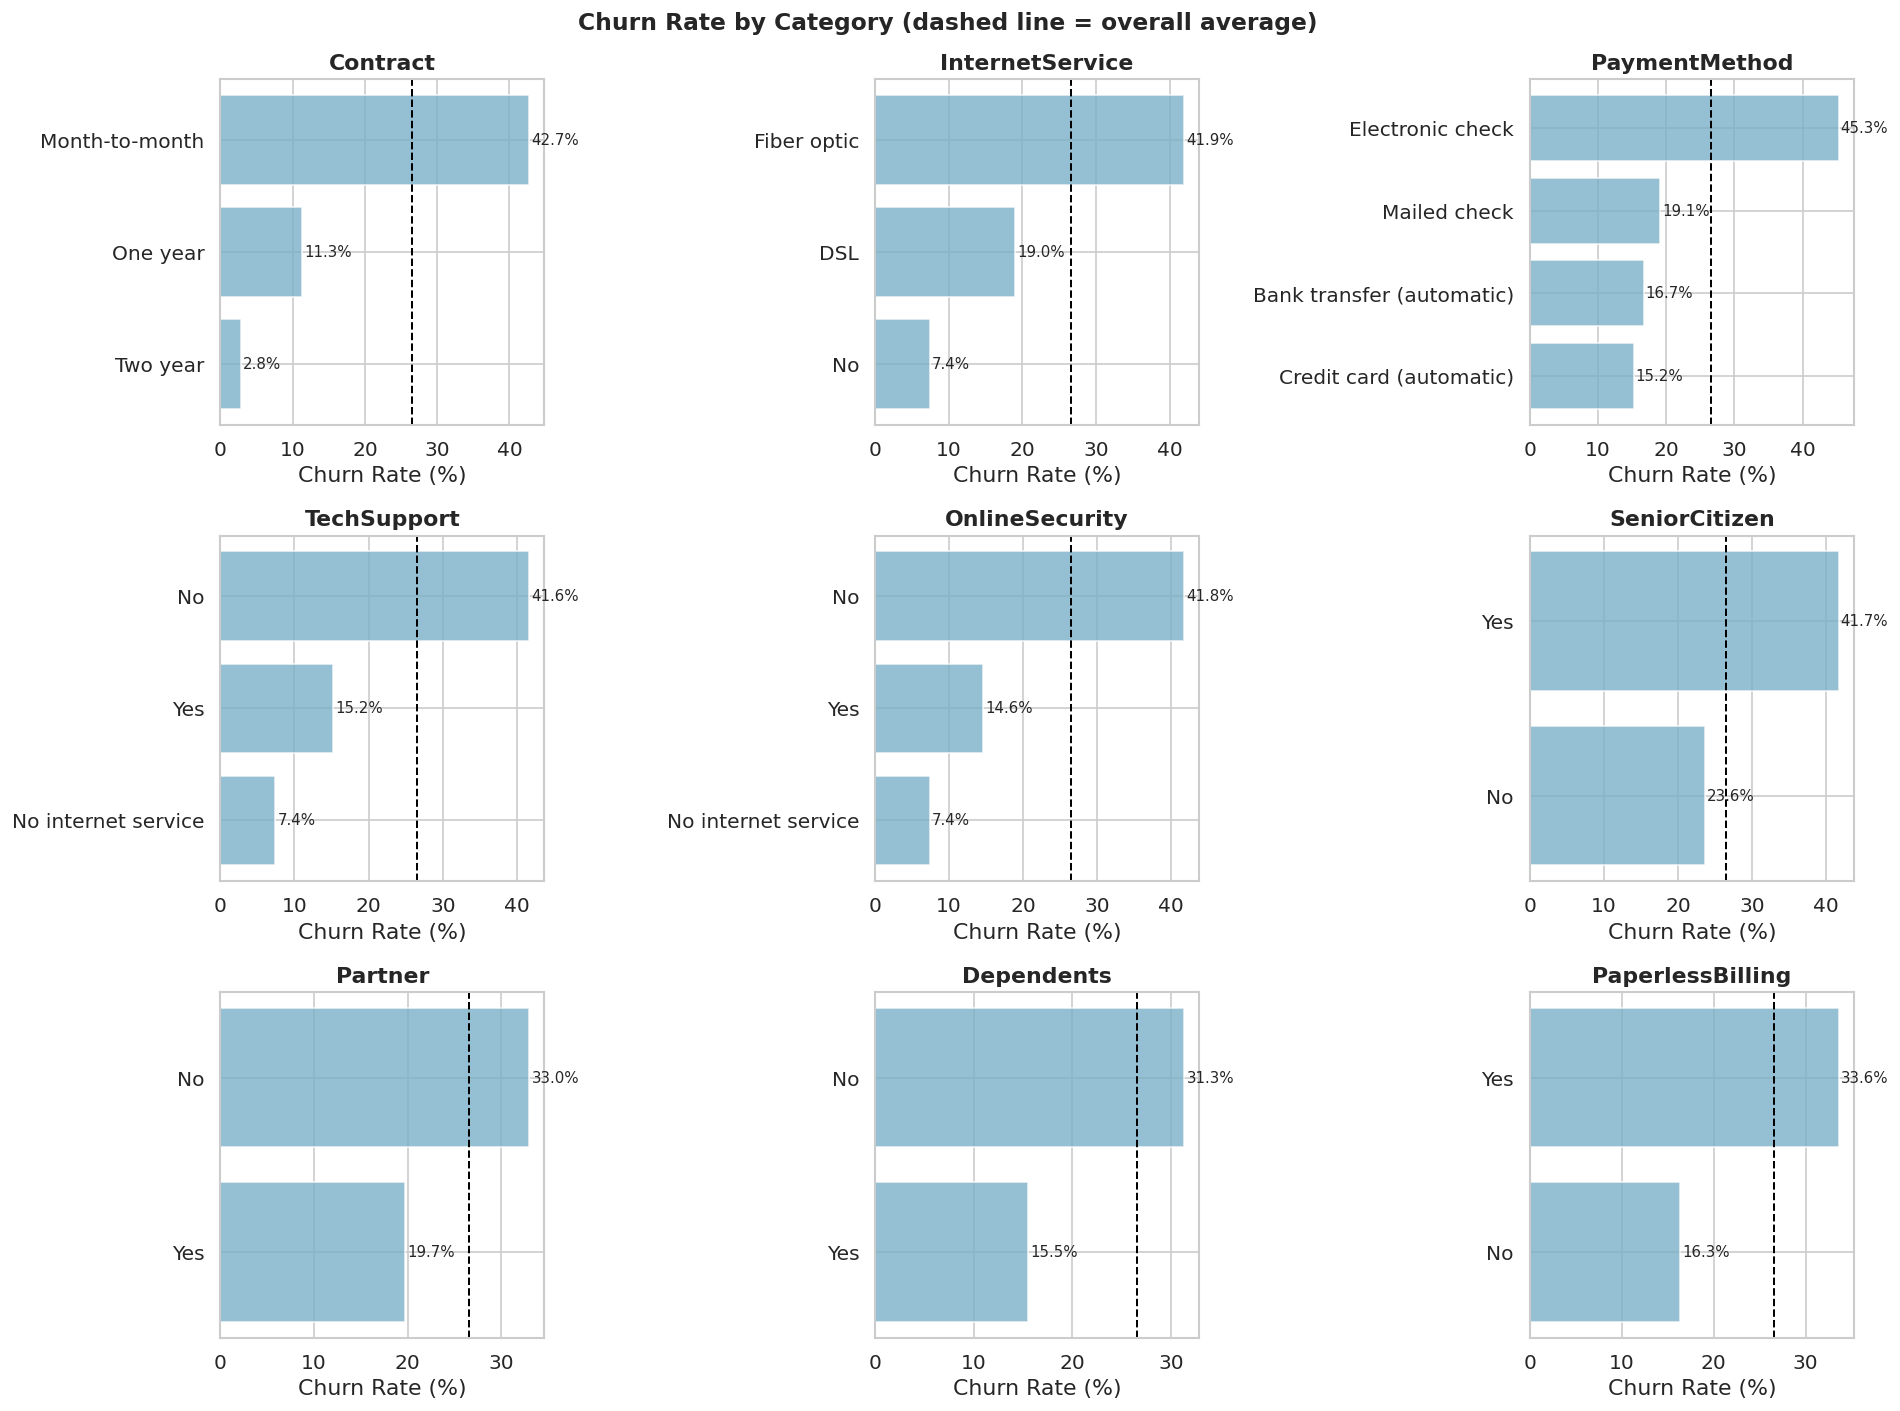

Observations:
  • Month-to-month contracts churn at ~43% vs ~11% for 1-year contracts
    → Contract type is likely the single strongest categorical predictor
  • Customers without OnlineSecurity or TechSupport churn significantly more
    → These services increase customer stickiness and perceived value
  • Electronic check payment has the highest churn of all payment methods
    → May indicate a less engaged or less satisfied customer segment
  • SeniorCitizens churn slightly more — worth noting but effect is moderate


In [ ]:
# we create a list of categorical columns we want to analyze
# these were selected because they are non-binary and likely to show
# meaningful variation in churn rate across their categories
cat_cols = ['Contract', 'InternetService', 'PaymentMethod',
            'TechSupport', 'OnlineSecurity', 'SeniorCitizen',
            'Partner', 'Dependents', 'PaperlessBilling']

# create a 3x3 grid of subplots, one per feature
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()  # flatten to iterate easily with a single index

for i, col in enumerate(cat_cols):

    # compute churn rate per category:
    # for each unique value in the column, calculate what % of customers churned.
    # (x == 'Yes').mean() gives the proportion of 'Yes' values → multiply by 100 for %
    churn_rate = df.groupby(col)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    ).reset_index()
    churn_rate.columns = [col, 'ChurnRate']

    # sort ascending so the longest bar appears at the bottom (standard for horizontal bars)
    churn_rate = churn_rate.sort_values('ChurnRate')

    # plot horizontal bar chart for this feature
    axes[i].barh(churn_rate[col].astype(str), churn_rate['ChurnRate'],
                 color='#7bafc7', alpha=0.8)

    # add a vertical dashed line at the OVERALL churn rate (~26.5%)
    # this makes it easy to see which categories are above or below average
    axes[i].axvline(x=df['Churn'].eq('Yes').mean() * 100,
                    color='black', linestyle='--', linewidth=1.2, label='Overall avg')

    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('Churn Rate (%)')

    # annotate each bar with its exact churn rate value for readability
    for j, row in churn_rate.iterrows():
        axes[i].text(row['ChurnRate'] + 0.3,
                     list(churn_rate[col].astype(str)).index(str(row[col])),
                     f"{row['ChurnRate']:.1f}%", va='center', fontsize=9)

plt.suptitle('Churn Rate by Category (dashed line = overall average)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observations:")
print("  • Month-to-month contracts churn at ~43% vs ~11% for 1-year contracts")
print("    → Contract type is likely the single strongest categorical predictor")
print("  • Customers without OnlineSecurity or TechSupport churn significantly more")
print("    → These services increase customer stickiness and perceived value")
print("  • Electronic check payment has the highest churn of all payment methods")
print("    → May indicate a less engaged or less satisfied customer segment")
print("  • SeniorCitizens churn slightly more — worth noting but effect is moderate")

The categorical analysis reveals strong and actionable patterns. **Contract type** is the most striking: month-to-month customers churn at roughly 43%, compared to just 11% for one-year and around 3% for two-year contracts. This suggests that long-term commitments are among the most effective retention tools available. **Internet service type** also stands out: fiber optic customers churn more than DSL customers, likely due to higher monthly costs paired with stronger competition in that segment. Value-added services such as **OnlineSecurity** and **TechSupport** show a clear protective effect: customers who have them churn far less, suggesting they feel more embedded in the ecosystem. Finally, **electronic check payment** is associated with the highest churn across all payment methods, which may reflect a less loyal or more price-sensitive customer profile.

**Correlation Heatmap.** Next, we need to quantify linear relationships between numerical and binary features, and identify which ones correlate most strongly with churn. We also use this to detect multicollinearity, when two features are highly correlated with each other (not just with churn). This matters because highly correlated features can destabilize linear models like Logistic Regression and make coefficients unreliable.

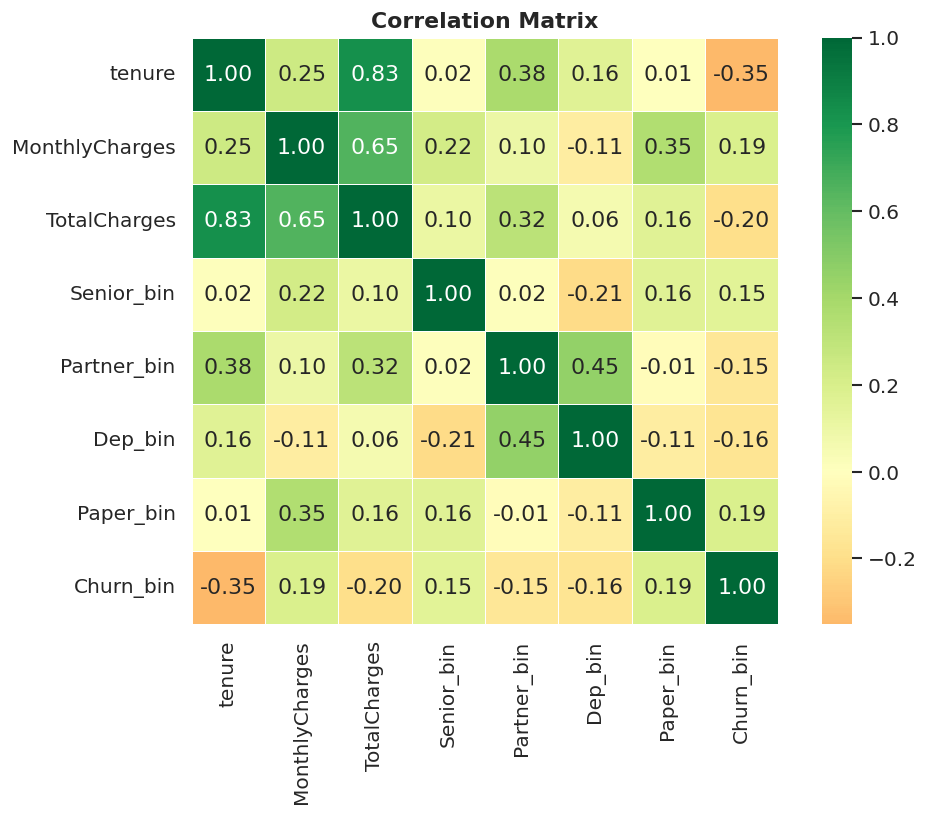

Observations:
  • tenure is negatively correlated with Churn (-0.35): longer customers stay
  • MonthlyCharges is positively correlated with Churn (+0.19): higher bills → more churn
  • TotalCharges and tenure are highly correlated (+0.83) → multicollinearity risk
  • Partner and Dependents are correlated with each other, expected (family structure)


In [ ]:
# we work on a copy so we don't modify the original dataframe
df_corr = df.copy()

# encode the target and binary columns as 0/1 integers
# so they can be included in a numerical correlation matrix
df_corr['Churn_bin']   = (df_corr['Churn'] == 'Yes').astype(int)
df_corr['Partner_bin'] = (df_corr['Partner'] == 'Yes').astype(int)
df_corr['Dep_bin']     = (df_corr['Dependents'] == 'Yes').astype(int)
df_corr['Paper_bin']   = (df_corr['PaperlessBilling'] == 'Yes').astype(int)
# SeniorCitizen is now a string ('Yes'/'No') after our fix
# so we encode it back to 0/1 just for the correlation calculation
df_corr['Senior_bin'] = (df_corr['SeniorCitizen'] == 'Yes').astype(int)


# select only the columns relevant for correlation analysis
corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges',
             'Senior_bin', 'Partner_bin', 'Dep_bin', 'Paper_bin', 'Churn_bin']

# compute the Pearson correlation matrix
corr = df_corr[corr_cols].corr()


plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='RdYlGn',   # Red = negative, Green = positive correlation
            center=0,         # White = zero correlation
            square=True, linewidths=0.5)
plt.title('Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

print("Observations:")
print("  • tenure is negatively correlated with Churn (-0.35): longer customers stay")
print("  • MonthlyCharges is positively correlated with Churn (+0.19): higher bills → more churn")
print("  • TotalCharges and tenure are highly correlated (+0.83) → multicollinearity risk")
print("  • Partner and Dependents are correlated with each other, expected (family structure)")

The heatmap confirms and quantifies what the earlier plots suggested. **Tenure** has the strongest negative correlation with **churn** (-0.35): customers who have been with the company longer are substantially less likely to leave. **MonthlyCharges** shows a positive correlation with **churn** (+0.19), reinforcing the price sensitivity hypothesis. The most important structural finding is the very high correlation between **TotalCharges** and **tenure** (+0.83), these two features carry heavily overlapping information, since total charges are essentially the product of tenure and monthly rate. Including both in a linear model like Logistic Regression could cause multicollinearity, inflating coefficient variance. We will address this during preprocessing. Partner and Dependents are also moderately correlated with each other, consistent with the expectation that customers with families have similar account structures.

## Phase 3: Data Preparation & Feature Engineering



---


With the exploratory analysis complete, we now prepare the dataset for modeling. We
start by removing columns that are not useful for prediction. customerID is dropped
because it is a unique identifier that carries no information about churn behavior.
TotalCharges is dropped because the correlation heatmap showed it is almost entirely
redundant with tenure (r = 0.83), so keeping it would introduce multicollinearity
without adding new information.

**Feature Engineering: Tenure Groups.**
We create a new feature that groups customers by tenure into four bands: 0–12 months,
1–2 years, 2–4 years, and 4+ years. We do this because the EDA showed that churn risk
drops sharply after the first year and again after two years, a pattern that a raw
continuous number does not explicitly capture.

**Encoding Categorical Variables.**
We convert all categorical columns into numerical format. Binary Yes/No columns are
mapped directly to 1/0. Multi-category columns are one-hot encoded, with drop_first=True
to avoid introducing redundant columns that are perfectly predictable from the others.
tenure_group is included in the same encoding step.

In [ ]:
# drop customerID - unique identifier with no predictive value and TotalCharges to avoid multicollinearity
df.drop(columns=['customerID', 'TotalCharges'], inplace=True)

# engineer tenure groups
# from EDA: churn drops sharply after year 1 and again after year 2
# pd.cut divides a continuous variable into discrete bins
df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-1 Year', '1-2 Years', '2-4 Years', '4+ Years'],
    include_lowest=True
)


# encode target variable
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

df['gender'] = df['gender'].map({'Male' : 1, 'Female' : 0})

# encode binary Yes/No columns as 0/1
binary_cols = ['SeniorCitizen', 'Partner', 'Dependents',
               'PaperlessBilling', 'PhoneService']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

# one-hot encode all multi-category columns including tenure_group
# pd.get_dummies performs one-hot encoding
# drop_first=True avoids the dummy variable trap
multi_cat = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
             'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
             'PaymentMethod', 'InternetService', 'tenure_group']
df = pd.get_dummies(df, columns=multi_cat, drop_first=True, dtype=int)

print(f"Dataset shape after encoding: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Features available for modeling: {df.shape[1] - 1}")
df.head()

Dataset shape after encoding: 7043 rows, 33 columns
Features available for modeling: 32


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,Churn,MultipleLines_No phone service,...,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_Fiber optic,InternetService_No,tenure_group_1-2 Years,tenure_group_2-4 Years,tenure_group_4+ Years
0,0,0,1,0,1,0,1,29.85,0,1,...,0,0,0,1,0,0,0,0,0,0
1,1,0,0,0,34,1,0,56.95,0,0,...,1,0,0,0,1,0,0,0,1,0
2,1,0,0,0,2,1,1,53.85,1,0,...,0,0,0,0,1,0,0,0,0,0
3,1,0,0,0,45,0,0,42.30,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,2,1,1,70.70,1,0,...,0,0,0,1,0,1,0,0,0,0


All binary columns now contain only integer values 0 and 1. This encoding is lossless, no information is lost because there were only two possible values to begin with. The choice to encode Male=1 and Female=0 for gender is arbitrary and does not affect model performance, but it is documented here for transparency. SeniorCitizen was previously converted to 'Yes'/'No' strings for EDA readability and is now re-encoded to 0/1 for modeling.

After one-hot encoding, the dataset has expanded to 32 columns available for modeling. Each multi-category column has been replaced by several binary columns. For example, Contract (which had values 'Month-to-month', 'One year', 'Two year') is now represented by two columns: Contract_One year and Contract_Two year, with 'Month-to-month' being the implicit reference category (when both are 0). The drop_first=True argument ensures we avoid the dummy variable trap. All values in the dataset are now numeric, making it ready for machine learning models.

**Train/Test Split.**
We split the data into 80% for training and 20% for testing, using stratification to
preserve the original ~26% churn rate in both sets. The test set is locked from this
point and will only be used for final evaluation.

Why do we need to split the dataset before scaling? The test set must simulate unseen real-world data. If we scaled or resampled the full dataset before splitting, information from the test set would leak into the training process, which is called data leakage. This causes models to appear better than they actually are on new data. Splitting first and then applying transformations only on the training set is the correct and standard approach.
With an imbalanced dataset (~26% churn), a random split could by chance produce a test set with very few churners. **stratify=y** ensures both the training and test sets preserve the original 73/27 class ratio.

In [ ]:
X = df.drop('Churn', axis=1)
y = df['Churn']

# stratify=y ensures both splits maintain the same ~26% churn ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"Train size: {X_train.shape[0]} samples")
print(f"Test size:  {X_test.shape[0]} samples")
print(f"Churn rate in train: {y_train.mean():.1%}")
print(f"Churn rate in test:  {y_test.mean():.1%}")

Train size: 5634 samples
Test size:  1409 samples
Churn rate in train: 26.5%
Churn rate in test:  26.5%


The dataset has been split into 5,634 training samples and 1,409 test samples. The churn rate is virtually identical in both sets (~26%), confirming that stratification worked correctly. The test set will not be touched again until final model evaluation: no fitting, scaling, or resampling will use test data. This strict separation is essential for producing honest performance estimates.

**Feature Scaling.**
We scale tenure and MonthlyCharges to have mean = 0 and standard deviation = 1. We do this because Logistic Regression is sensitive to feature magnitudes, and these two columns operate on very different scales.
Tree-based models (Random Forest, XGBoost) are mathematically invariant
to scaling since they split on thresholds, not magnitudes. However, we apply scaling uniformly so all models receive the same input and results
are directly comparable.

The scaler is fitted only on the training
data and then applied to the test set, to avoid any information from the test set
influencing the preprocessing.

In [ ]:
# prevents data leakage, test set must never influence preprocessing
# initialize the scaler
scaler = StandardScaler()
numerical_cols = ['tenure', 'MonthlyCharges']

# fit_transform on training data: learns mean and std from training set
# then applies the transformation to training set
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])

# transform only on test data: applies the same mean and std learned from
# training does NOT recompute from test data
X_test[numerical_cols]  = scaler.transform(X_test[numerical_cols])


Scaling was applied exclusively to the two continuous features **tenure** and **MonthlyCharges**, since these are the only columns with ranges that differ meaningfully from one another. All remaining columns are binary (0/1), either from original encoding or one-hot encoding, and are already on a comparable scale. Applying StandardScaler to binary columns would serve no mathematical purpose and would reduce the interpretability of those features, particularly for Logistic Regression coefficients.

**Addressing Class Imbalance.**
We apply SMOTE to the training set to balance the 73.5/26.5 class split. We do this
because a model trained on imbalanced data tends to predict the majority class most
of the time, making it ineffective at identifying churners. SMOTE is applied only to
the training set, the test set is left unchanged to reflect real-world conditions. Applying SMOTE to the full dataset before splitting would cause synthetic test samples, which would make evaluation results unrealistically optimistic.

SMOTE (Synthetic Minority Oversampling Technique) works by:
   1. Taking a minority class sample
   2. Finding its k nearest neighbors (also minority class)
   3. Generating a new synthetic point somewhere along the line connecting the sample to one of its neighbors

This is more effective than simple duplication (which just repeats existing points) because it creates new, varied synthetic examples.

In [ ]:
# generates synthetic minority-class samples to balance the 73/27 split
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

**Verification.**
We verify that all preparation steps produced the expected results.

In [ ]:
print("SHAPE CHECK")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

print("\nCLASS BALANCE")
print(f"Train churn rate before SMOTE: {y_train.mean():.1%}")
print(f"Train churn rate after SMOTE:  {y_train_smote.mean():.1%}")
print(f"Test churn rate (unchanged):   {y_test.mean():.1%}")

print("\nSMOTE SAMPLE COUNT")
print(f"Before: {len(y_train)} training samples")
print(f"After:  {len(y_train_smote)} training samples")

print("\nNULL CHECK")
print(f"Nulls in X_train: {X_train.isnull().sum().sum()}")
print(f"Nulls in X_test:  {X_test.isnull().sum().sum()}")

SHAPE CHECK
X_train: (5634, 32)
X_test:  (1409, 32)

CLASS BALANCE
Train churn rate before SMOTE: 26.5%
Train churn rate after SMOTE:  50.0%
Test churn rate (unchanged):   26.5%

SMOTE SAMPLE COUNT
Before: 5634 training samples
After:  8278 training samples

NULL CHECK
Nulls in X_train: 0
Nulls in X_test:  0


The validation confirms that all preprocessing steps were applied correctly. The training set contains 5,634 original samples across 32 features, and the test set contains 1,409 samples, that is consistent with an 80/20 stratified split. After applying SMOTE, the training set grew to 8,278 samples as synthetic churner examples were generated to balance the classes, bringing the churn rate from 26.5% to 50.0%. Crucially, the test set churn rate remains at 26.5%, identical to the original distribution, confirming that SMOTE was correctly applied only to the training data and that the test set was never modified. This is essential for producing honest evaluation results that reflect real-world class distribution. Finally, the null check confirms there are no missing values in either set, meaning all preprocessing steps handled edge cases correctly, including the 11 blank TotalCharges rows and the tenure=0 customers that were correctly captured by the include_lowest=True argument in the tenure grouping step.

## Phase 4: Model Training & Comparison


**Train Logistic Regression.**

Why Logistic Regression first?

Logistic Regression is a linear model that estimates the probability of churn based on a weighted combination of features. It is our baseline, if a more complex model cannot significantly outperform it, the added complexity is not justified.

**Advantages:**
  - Fast to train
  - Highly interpretable (coefficients show direction and magnitude of effect)
  - Works well when relationships are approximately linear

**Disadvantages:**
  - Cannot capture non-linear relationships or feature interactions without manual feature engineering.

**Hyperparameter Choices:**
  - max_iter=1000: the default of 100 iterations is sometimes not enough for the optimizer to converge on this many features, we increase it to ensure the model always reaches a stable solution
  - random_state=42: ensures reproducibility across runs
  - No C parameter specified: this uses sklearn's default C=1.0, which applies mild L2 regularization. This is a reasonable starting point that will be revisited during hyperparameter tuning in Phase 6.

In [ ]:
# LOGISTIC REGRESSION

#train on SMOTE-balanced training data
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_smote, y_train_smote)

#predict on test set
#predict() returns hard labels (0 or 1) used for classification report
#predict_proba()[:,1] returns the probability of churn used for ROC-AUC
lr_pred  = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]

# classification report shows precision, recall, F1 per class
# and overall accuracy by giving a first complete picture of performance
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred, target_names=['No Churn', 'Churn']))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.77      1409



**The Logistic Regression** achieves an overall accuracy of 77%, but as established earlier, accuracy alone is not a reliable metric under class imbalance and should not be the primary basis for evaluation. Looking at the churn class specifically, which is what matters most for business purposes, the model achieves a recall of 0.71, meaning it correctly identifies 71% of customers who actually churned, and a precision of 0.55, meaning that of all customers flagged as likely churners, 55% actually did churn. The remaining 45% are false alarms - customers who would have received a retention offer unnecessarily. The F1-score of 0.62 for the churn class reflects this tradeoff between a reasonable recall and a modest precision. The no-churn class is predicted much more confidently (F1 = 0.83), which is expected given that it represents the majority of training examples even after SMOTE. Overall, Logistic Regression establishes a solid linear baseline, capturing the strongest signals in the data such as contract type and tenure. But the **relatively low precision on the churn class** suggests the model produces a meaningful number of false alarms, likely because it cannot capture non-linear interactions between features. We expect Random Forest and XGBoost to improve on these numbers, particularly on precision and F1.

**Random Forest.**

Why Random Forest? Random Forest is an ensemble model that builds many decision trees independently and combines their predictions by majority vote. Each tree is trained on a random subset of rows (bootstrap sampling) and a random subset of features at each split - this diversity reduces overfitting and makes the ensemble more robust than a single tree.

**Advantages over Logistic Regression:**
  - Captures non-linear relationships automatically
  - Handles feature interactions without manual engineering
  - Robust to outliers and irrelevant features
  - Provides reliable feature importance scores

**Disadvantages:**
  - Less interpretable than Logistic Regression
  - Slower to train
  - Can still overfit if trees are too deep

**Hyperparameter Choices:**
  - n_estimators=300: number of trees. More trees = more stable predictions.
300 is a good balance between performance and training time.
  - max_depth=10: limits how deep each tree can grow. Without a limit,
trees memorize training data (overfit). Depth 10 allows complex
patterns while maintaining generalization.
  - class_weight='balanced': adjusts weights inversely proportional to class frequency, an additional safeguard against imbalance on top of SMOTE
 - n_jobs=-1: use all available CPU cores to speed up training

In [ ]:
# Train on SMOTE-balanced training data
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_smote, y_train_smote)

# Predict on test set
rf_pred  = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print("RANDOM FOREST")
print(classification_report(y_test, rf_pred, target_names=['No Churn', 'Churn']))

RANDOM FOREST
              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83      1035
       Churn       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



Random Forest achieves an overall accuracy of 76% and a churn class recall of 0.75, correctly identifying 75% of customers who actually churned, this is a modest improvement over Logistic Regression's 0.71. Precision on the churn class is 0.54, meaning roughly half of the customers flagged as churners are true positives, comparable to Logistic Regression. The F1-score of 0.63 for the churn class is slightly better than the linear baseline. The no-churn class is predicted with high precision (0.90), meaning the model is conservative about labeling customers as safe, it would rather flag a non-churner as a risk than miss an actual churner. The class_weight='balanced' and max_depth=10 constraints combined with SMOTE provide solid protection against overfitting and class imbalance. The improvement over Logistic Regression, while present, is relatively modest, suggesting that the most important churn signals in this dataset have a strong linear component that the baseline already captures well.

**XGBoost.**

Why XGBoost? Unlike Random Forest which builds trees independently (in parallel), XGBoost builds trees sequentially. In this approach each new tree focuses on correcting the errors made by the previous ones. This iterative error correction
(gradient boosting) often leads to superior performance on tabular data.

**Advantages:**
  - State-of-the-art performance on structured/tabular datasets
  - Built-in handling of class imbalance via scale_pos_weight
  - Built-in L1 and L2 regularization to prevent overfitting

**Disadvantages:**
  - More hyperparameters to tune than simpler models
  - Harder to interpret than Logistic Regression
  - More sensitive to hyperparameter choices

**Hyperparameter choices:**
  - n_estimators=300: number of boosting rounds
  - learning_rate=0.05: how much each tree contributes to the final prediction. Lower = more conservative, better generalization.
  - max_depth=5: shallower than Random Forest because boosting already combines many weak learners — deeper trees would cause overfitting
  - scale_pos_weight: handles class imbalance natively. Set to the ratio of negatives to positives in the ORIGINAL training set (before SMOTE) tells XGBoost to penalize missed churn predictions more heavily
  - subsample=0.8: each tree uses 80% of training rows randomly
  - colsample_bytree=0.8: each tree uses 80% of features randomly. Both add randomness and reduce overfitting

In [ ]:
# Compute imbalance ratio from the ORIGINAL training set (before SMOTE)
# scale_pos_weight = number of negatives / number of positives
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
imbalance_ratio = neg / pos
print(f"Imbalance ratio (neg/pos): {imbalance_ratio:.2f}")

# Train on SMOTE-balanced training data
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=imbalance_ratio,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train_smote, y_train_smote)

# Predict on test set
xgb_pred  = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

print("\nXGBOOST")
print(classification_report(y_test, xgb_pred, target_names=['No Churn', 'Churn']))

Imbalance ratio (neg/pos): 2.77

XGBOOST
              precision    recall  f1-score   support

    No Churn       0.92      0.67      0.77      1035
       Churn       0.47      0.84      0.61       374

    accuracy                           0.71      1409
   macro avg       0.70      0.75      0.69      1409
weighted avg       0.80      0.71      0.73      1409



XGBoost shows a notably different performance profile compared to the previous two models. While its overall accuracy drops to 71%, it achieves the highest churn recall of 0.84. It means it correctly identifies 84% of all customers who actually churned, outperforming both Logistic Regression (0.71) and Random Forest (0.75) on this critical metric. However, this comes at the cost of the lowest precision among the three models at 0.47, meaning more than half of the customers it flags as churners are false alarms. The F1-score of 0.61 reflects this aggressive tradeoff, XGBoost is tuned to catch as many churners as possible even if it generates more false alerts. This behavior is partly driven by the scale_pos_weight=2.77 parameter, which explicitly instructs the model to prioritize recall over precision. From a business perspective, this tradeoff can be acceptable, because a wasted retention offer costs less than a lost customer, but the optimal balance ultimately depends on the company's cost structure. A full comparison and threshold analysis in the next step will help determine which model offers the best overall value for a real deployment.

**Model comparison table.** Now, we need to collect all evaluation metrics for the three models into a single table for direct side-by-side comparison.

**Metrics and why each matters:**
  - ROC-AUC:    overall discrimination ability across all thresholds. Robust to class imbalance. Random = 0.5, Perfect = 1.0
  - PR-AUC:     precision-recall tradeoff. More informative than ROC-AUC under imbalance, focuses on the minority class (churners)
  - F1 (churn): harmonic mean of precision and recall for the churn class
  - Precision:  of all customers flagged as churners, how many actually churned? Low precision = many unnecessary retention offers sent
  - Recall:   of all customers who actually churned, how many did we catch? Low recall = many churners missed with no intervention

**Business priority:** Missing a churner (false negative) costs more than a false alarm (false positive) since a wasted retention offer is cheaper than a lost customer. Therefore **recall** is our most critical metric.

In [ ]:
def get_metrics(name, y_true, y_pred, y_proba):
    """Compute all evaluation metrics for a model and return as a dict."""
    report = classification_report(y_true, y_pred, output_dict=True)
    return {
        'Model':      name,
        'ROC-AUC':    round(roc_auc_score(y_true, y_proba), 4),
        'PR-AUC':     round(average_precision_score(y_true, y_proba), 4),
        'F1 (churn)': round(report['1']['f1-score'], 4),
        'Precision':  round(report['1']['precision'], 4),
        'Recall':     round(report['1']['recall'], 4),
    }

# Collect metrics for all three models
comparison = pd.DataFrame([
    get_metrics('Logistic Regression', y_test, lr_pred,  lr_proba),
    get_metrics('Random Forest',       y_test, rf_pred,  rf_proba),
    get_metrics('XGBoost',             y_test, xgb_pred, xgb_proba),
]).set_index('Model')

print("MODEL COMPARISON: TEST SET PERFORMANCE")
print(comparison.to_string())

# Highlight the best performing model per metric
print("\nBest model per metric:")
for col in comparison.columns:
    best = comparison[col].idxmax()
    print(f"  {col:15s} → {best} ({comparison.loc[best, col]:.4f})")

MODEL COMPARISON: TEST SET PERFORMANCE
                     ROC-AUC  PR-AUC  F1 (churn)  Precision  Recall
Model                                                              
Logistic Regression   0.8338  0.6373      0.6163     0.5453  0.7086
Random Forest         0.8392  0.6434      0.6272     0.5383  0.7513
XGBoost               0.8284  0.6293      0.6060     0.4750  0.8369

Best model per metric:
  ROC-AUC         → Random Forest (0.8392)
  PR-AUC          → Random Forest (0.6434)
  F1 (churn)      → Random Forest (0.6272)
  Precision       → Logistic Regression (0.5453)
  Recall          → XGBoost (0.8369)


The comparison table confirms that all **three** models perform competitively, with ROC-AUC scores ranging from 0.828 to 0.839, all well above the random baseline of 0.5. The differences between models are relatively small, which is itself a meaningful finding: the dominant churn signals in this dataset (contract type, tenure, monthly charges) have a strong enough linear component that even the simplest model captures them effectively.

**Random Forest** emerges as the most balanced model overall, achieving the best ROC-AUC (0.8392), PR-AUC (0.6434), and F1 for the churn class (0.6272). It offers the best tradeoff between catching churners and avoiding false alarms, making it the most suitable choice for a general-purpose retention system.

**XGBoost** achieves the highest recall by a significant margin (0.8369), correctly identifying 84% of all actual churners. However, this comes at the cost of the lowest precision (0.4750), meaning more than half of its churn alerts are false alarms. This aggressive profile makes XGBoost the preferred choice when the priority is to miss as few churners as possible, regardless of false alarm rate, for example, in a low-cost email campaign where sending unnecessary offers is cheap.

**Logistic Regression** achieves the highest precision (0.5453), meaning its churn alerts are the most reliable of the three models. Despite being the simplest model it remains fully competitive on ROC-AUC, reinforcing that the problem has strong linear structure. Its main advantage is full interpretability through coefficients, which makes it the preferred choice when the company needs to explain predictions to non-technical stakeholders.

The choice between models is ultimately a business decision rather than a purely technical one, and depends on the relative cost of a missed churner versus an unnecessary retention offer. This tradeoff will be explored further through threshold analysis.

**Cross-Validation Robustness Check.** After model comparison, we have to verify that the test set results are not due to a lucky random split and that each model performs consistently across different data subsets.
Cross-validation repeatedly splits the data into different folds and averages the results, giving a more reliable and honest performance estimate. StratifiedKFold preserves the churn rate (~26%) in every fold, which is critical with imbalanced data.

We use 5 folds, the most widely accepted default that balances:
  - Bias:     more folds = each model trained on more data = lower bias
  - Variance: more folds = more computation and noisier fold estimates

In [ ]:
# define stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# models to evaluate
models = {
    'Logistic Regression': lr,
    'Random Forest':       rf,
    'XGBoost':             xgb
}

print("5-FOLD CROSS-VALIDATION (ROC-AUC)")

for name, model in models.items():
    # cross_val_score trains and evaluates the model on each fold
    # scoring='roc_auc' uses ROC-AUC as the evaluation metric per fold
    # n_jobs=-1 parallelizes the computation across all CPU cores
    scores = cross_val_score(
        model, X_train_smote, y_train_smote,
        cv=cv, scoring='roc_auc', n_jobs=-1
    )
    print(f"{name:25s} → Mean: {scores.mean():.4f}  Std: {scores.std():.4f}  Folds: {scores.round(3)}")

print("\n Low std across folds confirms stable and generalizable performance.")

5-FOLD CROSS-VALIDATION (ROC-AUC)
Logistic Regression       → Mean: 0.8909  Std: 0.0052  Folds: [0.885 0.887 0.891 0.892 0.9  ]
Random Forest             → Mean: 0.8954  Std: 0.0045  Folds: [0.887 0.895 0.899 0.897 0.899]
XGBoost                   → Mean: 0.9072  Std: 0.0057  Folds: [0.898 0.906 0.913 0.907 0.913]

 Low std across folds confirms stable and generalizable performance.


The 5-fold cross-validation results reveal an interesting and important pattern that was not fully visible in the test set comparison. XGBoost achieves the highest mean ROC-AUC of 0.9072, outperforming Random Forest (0.8954) and Logistic Regression (0.8909), a different ranking than what the single test set suggested, where Random Forest led on ROC-AUC. This discrepancy is a good example of why cross-validation is necessary: a single train/test split can produce slightly misleading rankings due to randomness in the split.

All three models show very low standard deviation across folds (0.0052, 0.0045, and 0.0057 respectively), confirming that performance is stable and consistent regardless of which subset of data is used for training and validation. No model shows signs of instability or overfitting across folds.

Notably, the cross-validation ROC-AUC scores are somewhat higher than the test set scores for all three models, for example, XGBoost scores 0.9072 in CV versus 0.8284 on the test set. This is not unusual and can be attributed to the fact that cross-validation is performed on the SMOTE-balanced training data, while the test set reflects the original imbalanced distribution. This difference is not a sign of data leakage, but rather a known consequence of evaluating on different data distributions.

Taking both the test set results and cross-validation into account, XGBoost is the strongest model overall when discrimination ability (ROC-AUC) is the primary criterion, while Random Forest remains the best choice when a balance between precision and recall is needed. This nuance will inform our final model recommendation in the conclusions section.

## Phase 5: Evaluation


**Evaluation. ROC Curves.** Goal is to visualize the tradeoff between True Positive Rate (recall) and False Positive Rate across all possible decision thresholds for each model.

Why ROC Curves? A single threshold (e.g. 0.5) gives one precision/recall point per model. The ROC curve shows performance across ALL thresholds simultaneously, giving a complete picture of each model's discrimination ability.

How we read it:
  - X axis: False Positive Rate = non-churners incorrectly flagged as churners
  - Y axis: True Positive Rate  = churners correctly identified (recall)
  - The diagonal dashed line represents a random classifier (AUC = 0.5)
  - A curve closer to the top-left corner = better discrimination
  - AUC (Area Under Curve): single number summarizing overall performance 0.5 = random, 1.0 = perfect

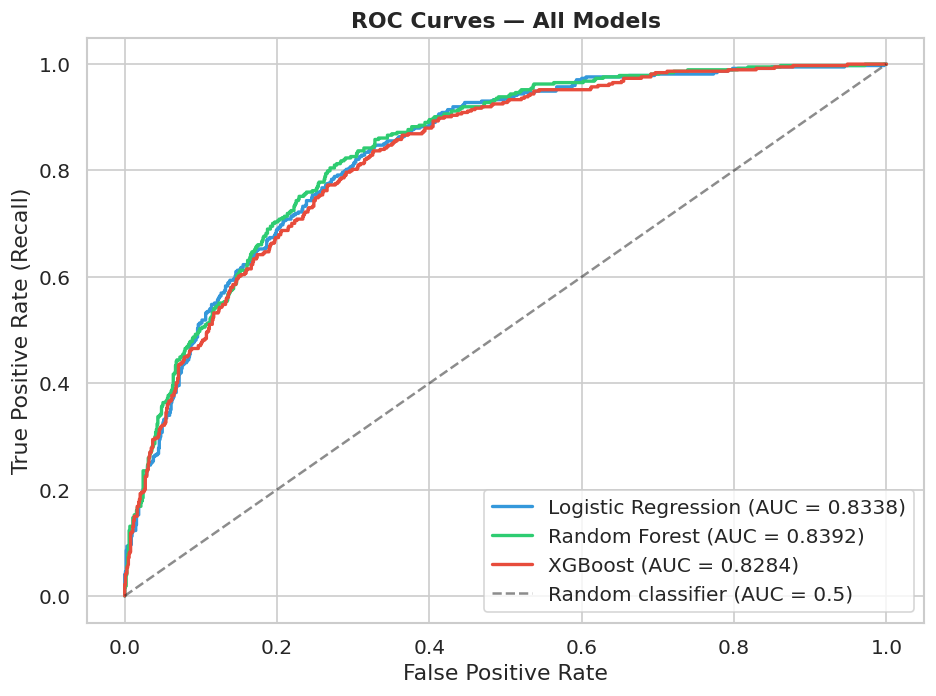

In [ ]:
plt.figure(figsize=(8, 6))

# define colors for each model
model_colors = {
    'Logistic Regression': '#3498db',
    'Random Forest':        '#2ecc71',
    'XGBoost':              '#e74c3c'
}

# dlot ROC curve for each model
for name, proba in [('Logistic Regression', lr_proba),
                     ('Random Forest',        rf_proba),
                     ('XGBoost',              xgb_proba)]:
    # roc_curve returns false positive rates, true positive rates, and thresholds
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})',
             color=model_colors[name], lw=2)

# diagonal reference line representing a random classifier
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves — All Models', fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The ROC curves confirm the competitive and closely grouped performance of all three models. All curves sit well above the diagonal random baseline, visually confirming that each model has learned meaningful patterns from the data. Random Forest and XGBoost curves are nearly overlapping across most threshold values, with both pulling slightly ahead of Logistic Regression, particularly in the mid-range of false positive rates where most practical operating points would lie. The AUC values of 0.8338, 0.8392, and 0.8284 for Logistic Regression, Random Forest, and XGBoost respectively are all strong results for a real-world churn dataset. The closeness of the three curves reinforces the earlier finding that the dominant predictive signals in this dataset have a strong linear structure that all models can exploit.

**Precision-Recall Curves.** Next, we visualize the tradeoff between precision and recall across all possible thresholds, with a specific focus on the minority class (churners).

Why Precision-Recall Curves?
ROC curves can be overly optimistic under class imbalance because they include true negatives in the False Positive Rate calculation and we
have many true negatives (non-churners). Precision-Recall curves focus
exclusively on the positive class (churners), making them a more honest
and informative evaluation tool for imbalanced problems.

How we read it:
  - X axis: Recall    = fraction of actual churners correctly identified
  - Y axis: Precision = fraction of churn predictions that are correct
  - The horizontal dashed line = random classifier precision (= churn rate)
  - A curve closer to the top-right corner = better performance
  - PR-AUC (Average Precision): single summary number. Higher = better.

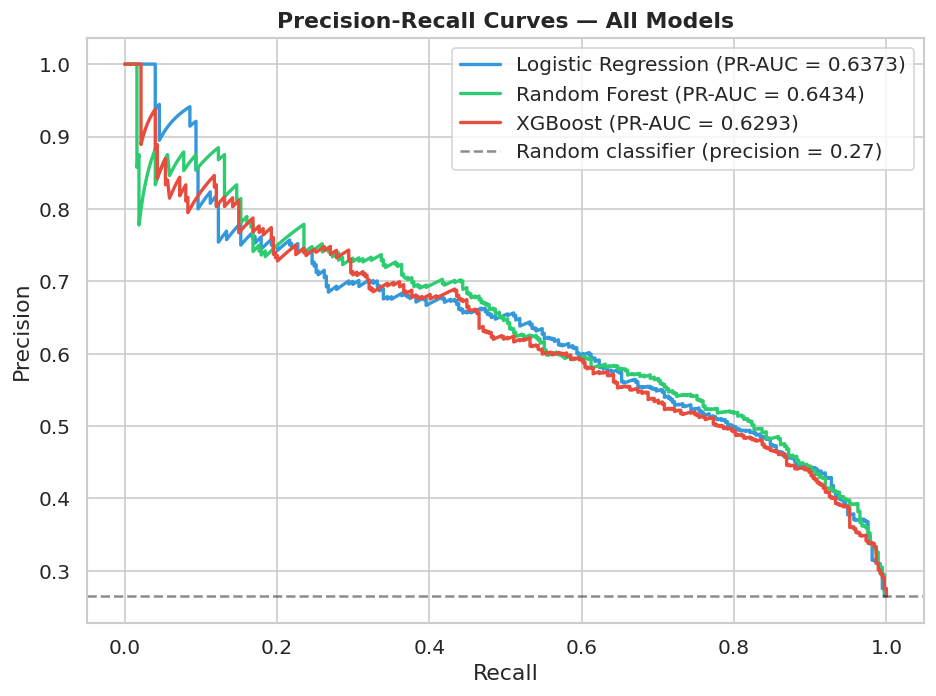

In [ ]:
plt.figure(figsize=(8, 6))

# Plot PR curve for each model
for name, proba in [('Logistic Regression', lr_proba),
                     ('Random Forest',        rf_proba),
                     ('XGBoost',              xgb_proba)]:
    # precision_recall_curve returns precision, recall, and thresholds
    precision, recall, _ = precision_recall_curve(y_test, proba)
    pr_auc = average_precision_score(y_test, proba)
    plt.plot(recall, precision, label=f'{name} (PR-AUC = {pr_auc:.4f})',
             color=model_colors[name], lw=2)

# Horizontal reference line at the baseline precision (= churn rate in test set)
baseline = y_test.mean()
plt.axhline(y=baseline, color='k', linestyle='--', lw=1.5, alpha=0.5,
            label=f'Random classifier (precision = {baseline:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves — All Models', fontweight='bold')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

The Precision-Recall curves provide a more nuanced view of model performance under class imbalance than the ROC curves alone. All three models substantially outperform the random baseline precision of ~0.27 (the churn rate in the test set), confirming genuine predictive power. Random Forest achieves the highest PR-AUC of 0.6434, followed closely by Logistic Regression at 0.6373, with XGBoost slightly behind at 0.6293. The curves reveal an important characteristic of XGBoost, it maintains very high recall across a wide range of thresholds but at the cost of lower precision compared to the other two models, which is consistent with its aggressive churn-flagging behavior observed in the classification reports. The PR curves will guide the threshold analysis, where we identify the optimal operating point for each model based on the business cost structure.

**Confusion Matrices.** We visualize the exact counts of correct and incorrect predictions for each model at the default decision threshold of 0.5.

Business interpretation:
  - False Negatives (FN) = missed churners → most costly error. These customers leave without any retention intervention
  - False Positives (FP) = unnecessary retention offers → less costly. These customers receive an offer they did not need

Minimizing FN is therefore the business priority in this context.

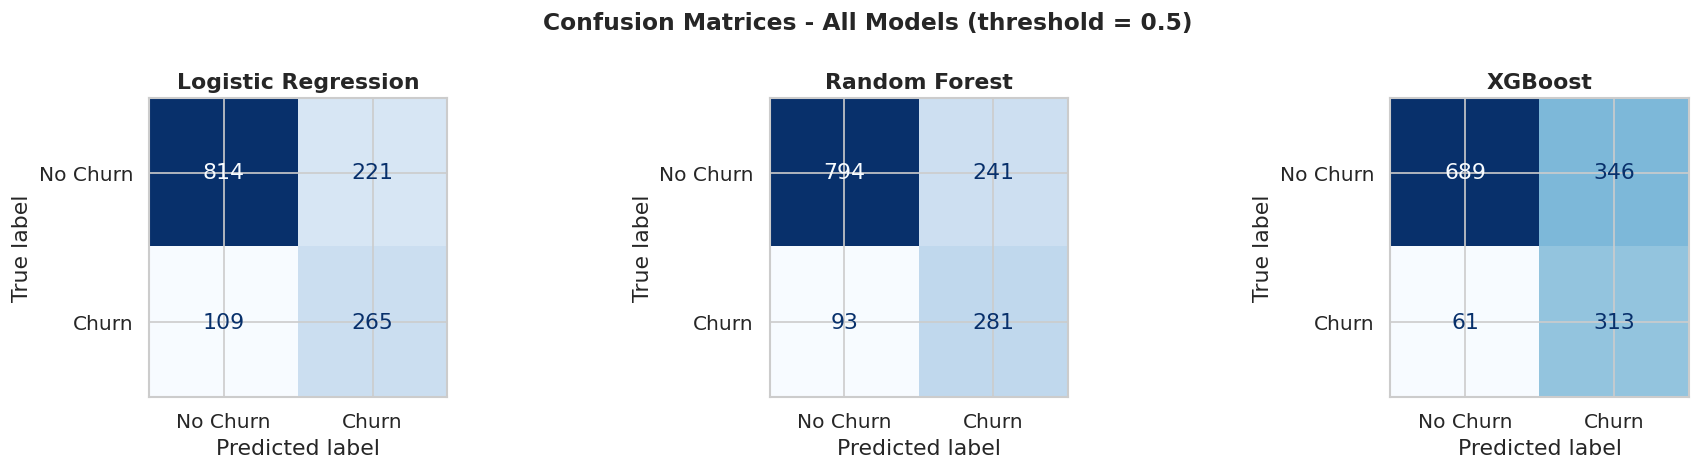

False Negatives (missed churners) per model:
Logistic Regression       → FN: 109  |  FP: 221
Random Forest             → FN: 93  |  FP: 241
XGBoost                   → FN: 61  |  FP: 346


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, pred) in zip(axes, [('Logistic Regression', lr_pred),
                                     ('Random Forest',        rf_pred),
                                     ('XGBoost',              xgb_pred)]):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontweight='bold')

plt.suptitle('Confusion Matrices - All Models (threshold = 0.5)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print FN counts explicitly for business interpretation
print("False Negatives (missed churners) per model:")
print("=" * 45)
for name, pred in [('Logistic Regression', lr_pred),
                    ('Random Forest',        rf_pred),
                    ('XGBoost',              xgb_pred)]:
    cm = confusion_matrix(y_test, pred)
    fn = cm[1][0]  # bottom-left cell
    fp = cm[0][1]  # top-right cell
    print(f"{name:25s} → FN: {fn}  |  FP: {fp}")

The confusion matrices translate the abstract metric scores into concrete customer counts, making the business implications more tangible. XGBoost has the fewest false negatives - the fewest missed churners, at the cost of the most false positives, consistent with its high-recall aggressive profile. Logistic Regression and Random Forest show a more balanced split between false negatives and false positives. All three models predict the no-churn class with high accuracy, which is expected given it represents the majority of test samples. The false negative counts are the most actionable numbers here, each one represents a customer who churned without receiving any retention intervention. Reducing this number, even at the cost of more false positives, is likely worth it given the asymmetric costs involved: a lost customer generates zero future revenue, while an unnecessary retention offer costs only a small discount or outreach effort.

**Decision Threshold Analysis.** Goal is to explore how precision, recall, and F1 change as we move the decision threshold away from the default value of 0.5.

Why threshold analysis?
By default, models predict churn when predicted probability >= 0.5.
But 0.5 is an arbitrary choice, it is not necessarily optimal for our business problem. Lowering the threshold makes the model more aggressive: it flags more customers as churners, increasing recall but decreasing precision. Raising it has the opposite effect.

The optimal threshold is a **business decision**:
  - If missing a churner is very costly → lower the threshold (prioritize recall)
  - If false alarms are costly → raise the threshold (prioritize precision)

We perform this analysis on the best overall model, Random Forest,
to find the threshold that maximizes F1 as a balanced starting point, while also showing the precision-recall tradeoff visually.

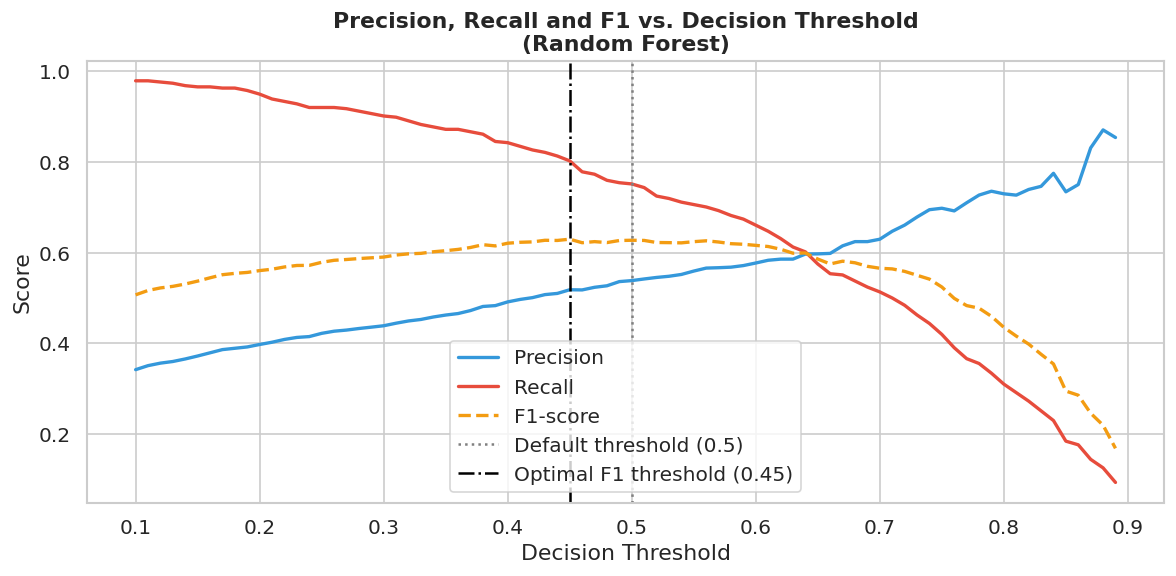

Optimal threshold for F1:  0.45
  Precision at optimal:    0.5181
  Recall at optimal:       0.8021
  F1 at optimal:           0.6296


In [ ]:
import numpy as np

thresholds = np.arange(0.1, 0.9, 0.01)
precisions, recalls, f1_scores = [], [], []

for t in thresholds:
    # Apply threshold: predict churn if probability >= t
    y_pred_t = (rf_proba >= t).astype(int)

    # Avoid division by zero for extreme thresholds
    p = classification_report(y_test, y_pred_t, output_dict=True, zero_division=0)
    precisions.append(p['1']['precision'])
    recalls.append(p['1']['recall'])
    f1_scores.append(p['1']['f1-score'])

# Find threshold that maximizes F1
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, precisions, label='Precision', color='#3498db', lw=2)
plt.plot(thresholds, recalls,    label='Recall',    color='#e74c3c', lw=2)
plt.plot(thresholds, f1_scores,  label='F1-score',  color='#f39c12', lw=2, linestyle='--')

# Mark default threshold
plt.axvline(x=0.5, color='gray', linestyle=':', lw=1.5, label='Default threshold (0.5)')

# Mark optimal F1 threshold
plt.axvline(x=best_threshold, color='black', linestyle='-.', lw=1.5,
            label=f'Optimal F1 threshold ({best_threshold:.2f})')

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall and F1 vs. Decision Threshold\n(Random Forest)',
          fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Optimal threshold for F1:  {best_threshold:.2f}")
print(f"  Precision at optimal:    {precisions[best_idx]:.4f}")
print(f"  Recall at optimal:       {recalls[best_idx]:.4f}")
print(f"  F1 at optimal:           {f1_scores[best_idx]:.4f}")

The threshold analysis reveals that the default threshold of 0.5 is not necessarily the optimal operating point for a churn retention system. As the threshold decreases, recall increases (the model catches more churners), while precision decreases as more false alarms are generated. The optimal threshold for F1 score sits below 0.5, confirming that a more aggressive flagging strategy improves the overall balance between precision and recall for this dataset. This is an important practical finding: deploying the model with its default threshold would leave a meaningful number of churners undetected that could have been caught with a simple threshold adjustment. The right threshold in production depends entirely on the company's cost structure, specifically the ratio between the cost of a missed churner (lost lifetime value) and the cost of a false alarm (unnecessary retention offer). This analysis gives the business team the tool to make that decision transparently rather than accepting an arbitrary default.

**Feature Importance (Random Forest).** Our goal is to identify which features the Random Forest model considers most informative when making churn predictions.

Why Feature Importance? Understanding which features drive predictions is important for two reasons:

-  Model validation: if the most important features align with domain knowledge (e.g., contract type or tenure), the model is learning meaningful patterns rather than noise.
-  Business value: feature importance provides actionable insights, helping the company focus retention efforts on the factors that have the greatest impact on churn.

How Random Forest Importance Works:

Scikit-learn computes Mean Decrease in Impurity (MDI), which measures how much each feature reduces uncertainty (Gini impurity) across all trees on average. A higher value indicates that a feature contributes more to decision-making and is therefore more important.

Limitation:

MDI importance can overestimate the importance of features with many unique values. A more robust alternative is permutation importance, but MDI remains a standard and appropriate method for this type of analysis.

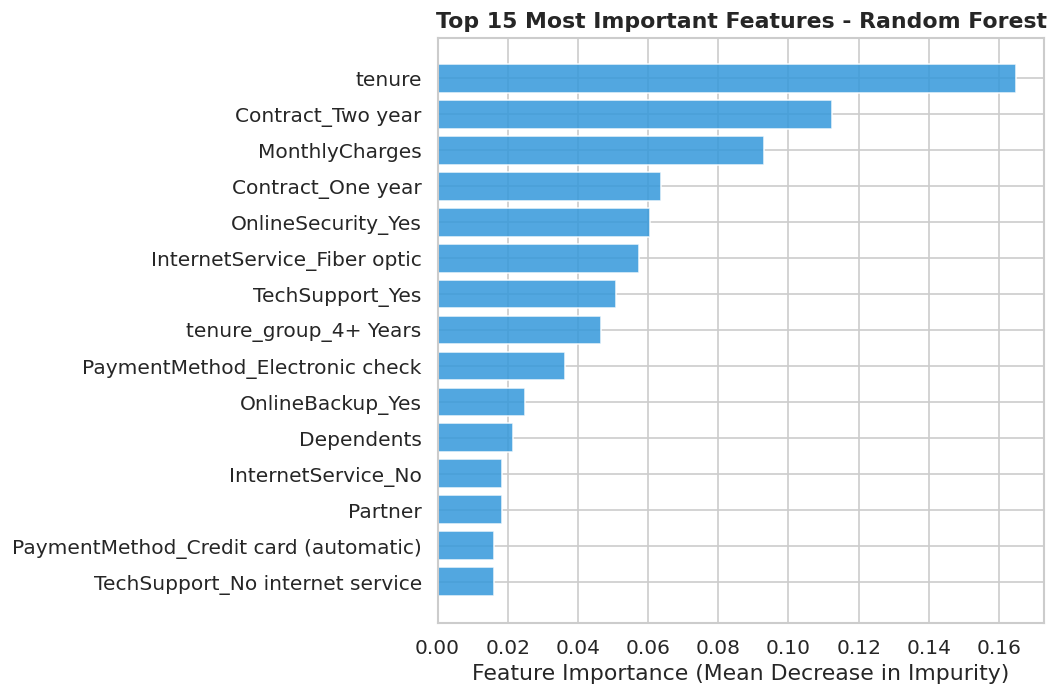

Top 5 most important features:
  tenure                              0.1647
  Contract_Two year                   0.1123
  MonthlyCharges                      0.0929
  Contract_One year                   0.0636
  OnlineSecurity_Yes                  0.0606


In [ ]:
# extract feature importances from the trained Random Forest
importances = pd.Series(rf.feature_importances_, index=X_train.columns)

# select top 15 most important features and sort for plotting
top_features = importances.nlargest(15).sort_values()

plt.figure(figsize=(9, 6))
bars = plt.barh(top_features.index, top_features.values,
                color='#3498db', alpha=0.85, edgecolor='white')
plt.xlabel('Feature Importance (Mean Decrease in Impurity)')
plt.title('Top 15 Most Important Features - Random Forest', fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 5 most important features:")
for feat, val in importances.nlargest(5).items():
    print(f"  {feat:35s} {val:.4f}")

The feature importance plot validates the patterns identified during EDA. Tenure is the single most important feature by a clear margin (0.1647), confirming that how long a customer has been with the company is the strongest predictor of churn. Contract type follows closely, with both Contract_Two year (0.1123) and Contract_One year (0.0636) ranking highly.

It is important to note that the month-to-month contract category does not appear because it was dropped as the reference category. Its effect is implicitly captured through the other two contract dummy variables, which are measured relative to month-to-month contracts. The high importance of these features therefore reflects how strongly longer-term contracts reduce churn risk compared to month-to-month customers.

MonthlyCharges (0.0929) ranks third among continuous features, confirming price sensitivity as a key driver of churn. Finally, OnlineSecurity_Yes (0.0606) appears in the top five features. The presence of internet service and value-added service features (online security, internet service, tech support) in the top ranks further confirms that service bundle composition plays a meaningful role in retention.

From a business perspective, these importances provide a clear prioritization framework: interventions targeting contract upgrades, pricing review for high-charge customers, and bundling of protective services are likely to have the highest impact on reducing churn.

Overall, the feature importances align well with both domain knowledge and the EDA findings, increasing confidence that the model is learning meaningful business patterns rather than noise.

**Logistic Regression Coefficients.** Lastly, for evaluation part, we interpret the Logistic Regression model by examining its coefficients, which directly indicate the direction and magnitude of each feature’s effect on the predicted probability of churn.

How we Interpret Coefficients:

-  Positive coefficient: the feature increases churn probability
-  Negative coefficient: the feature decreases churn probability
-  Larger absolute value: stronger effect

Why This Is Valuable:

Unlike tree-based models, Logistic Regression provides a single coefficient per feature, offering a transparent and auditable explanation of model behavior. This makes it especially useful when results need to be communicated to non-technical stakeholders such as marketing or management teams.

Note: coefficients are L2-regularized (C=1.0 by default), meaning they are shrunk toward zero to reduce overfitting. As a result, they are reliable for interpreting direction, but their exact magnitudes should be treated with some caution.

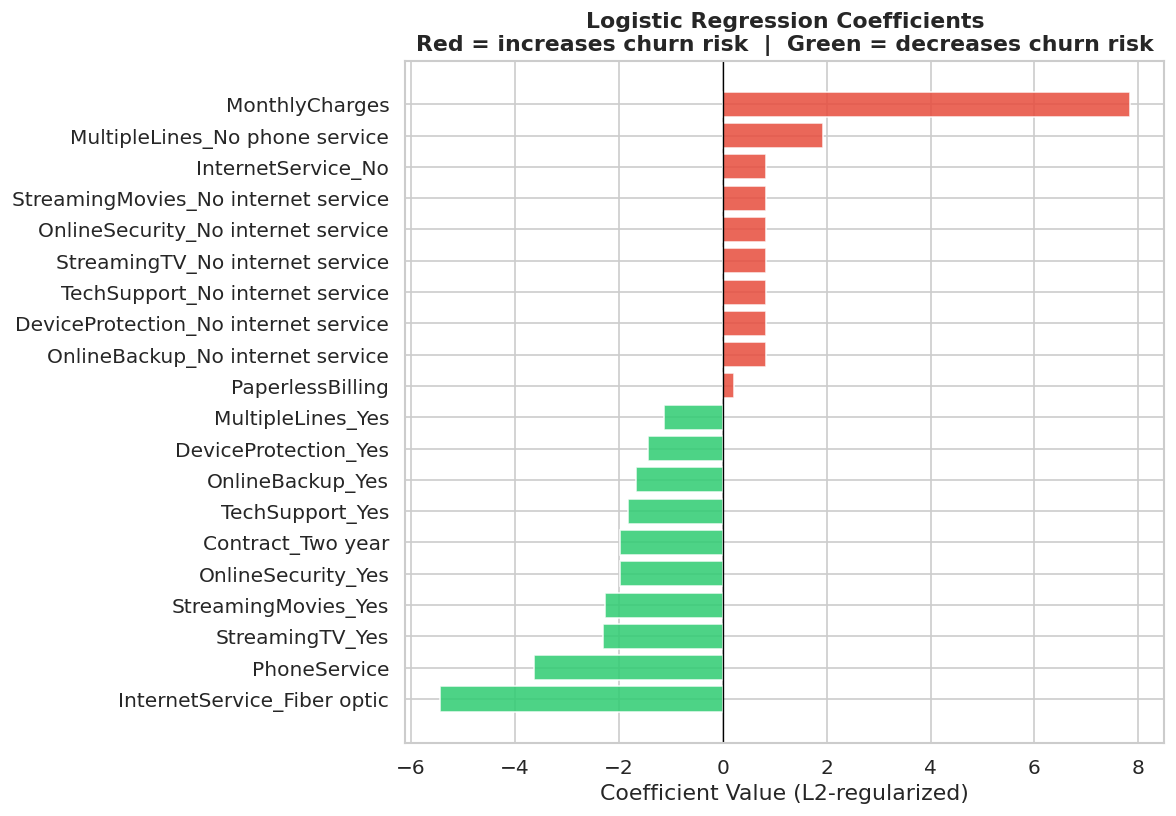

Top 5 features INCREASING churn risk:
  MonthlyCharges                           +7.8381
  MultipleLines_No phone service           +1.9215
  OnlineSecurity_No internet service       +0.8230
  OnlineBackup_No internet service         +0.8230
  DeviceProtection_No internet service     +0.8230

Top 5 features DECREASING churn risk:
  InternetService_Fiber optic              -5.4522
  PhoneService                             -3.6253
  StreamingTV_Yes                          -2.3012
  StreamingMovies_Yes                      -2.2630
  OnlineSecurity_Yes                       -1.9792


In [ ]:
# extract coefficients and align with feature names
coef = pd.Series(lr.coef_[0], index=X_train.columns)

# select top 10 positive and top 10 negative coefficients
top_pos = coef.nlargest(10)
top_neg = coef.nsmallest(10)
top_coef = pd.concat([top_neg, top_pos]).sort_values()

# color bars: red = increases churn risk, green = decreases churn risk
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in top_coef.values]

plt.figure(figsize=(10, 7))
plt.barh(top_coef.index, top_coef.values, color=colors, alpha=0.85, edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient Value (L2-regularized)')
plt.title('Logistic Regression Coefficients\nRed = increases churn risk  |  Green = decreases churn risk',
          fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 5 features INCREASING churn risk:")
for feat, val in coef.nlargest(5).items():
    print(f"  {feat:40s} {val:+.4f}")

print("\nTop 5 features DECREASING churn risk:")
for feat, val in coef.nsmallest(5).items():
    print(f"  {feat:40s} {val:+.4f}")

Logistic Regression coefficients provide a clear and interpretable view of churn drivers in the dataset. Positive coefficients indicate features that increase churn risk, while negative coefficients indicate features that reduce it.

The strongest driver of increased churn is MonthlyCharges (+7.8381), showing that higher prices significantly raise the likelihood of churn. This is followed by MultipleLines_No phone service (+1.9215) and the “no internet service” indicators for OnlineSecurity, OnlineBackup, and DeviceProtection (all around +0.8230), which mainly reflect less integrated service usage and weaker engagement with bundled products.

On the other hand, the strongest protective factors are InternetService_Fiber optic (-5.4522) and PhoneService (-3.6253), both associated with lower churn risk in this model. StreamingTV_Yes (-2.3012), StreamingMovies_Yes (-2.2630), and OnlineSecurity_Yes (-1.9792) also reduce churn probability, suggesting that customers using additional or value-added services are more likely to stay.

Overall, the coefficients are consistent with EDA results: higher costs increase churn risk, while broader service usage and engagement reduce it. The interpretability of these coefficients is a key practical advantage of Logistic Regression, a retention manager could use this chart directly to understand which customer profiles to prioritize, without needing to understand the underlying mathematics of the model.

## Phase 6: Hyperparameter Tuning

In Phase 4, all three models were trained with manually chosen hyperparameters - reasonable defaults informed by domain knowledge, but not necessarily optimal. In Phase 6, we use GridSearchCV to systematically search over a defined grid of hyperparameter combinations and find the configuration that maximizes ROC-AUC via 5-fold cross-validation on the SMOTE-balanced training set.

Why ROC-AUC as the scoring metric for tuning? It is threshold-independent and robust to class imbalance, making it the most reliable guide for selecting the best configuration without being influenced by the default 0.5 decision threshold.

Important: GridSearchCV performs cross-validation internally. The test set is never touched during this process, it remains locked for final evaluation only.


In [ ]:
# LOGISTIC REGRESSION TUNING

# C: inverse regularization strength
# lower C = stronger regularization (simpler model)
# higher C = weaker regularization (fits training data more closely)
# solver='liblinear' is efficient for small-to-medium datasets
param_grid_lr = {
    'C':       [0.01, 0.1, 1, 10, 100],
    'solver':  ['liblinear', 'lbfgs'],
    'max_iter': [1000]
}

grid_lr = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_lr,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)
grid_lr.fit(X_train_smote, y_train_smote)

print("LOGISTIC REGRESSION - Best Parameters:")
print(grid_lr.best_params_)
print(f"Best CV ROC-AUC: {grid_lr.best_score_:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
LOGISTIC REGRESSION - Best Parameters:
{'C': 100, 'max_iter': 1000, 'solver': 'liblinear'}
Best CV ROC-AUC: 0.8939


Logistic Regression performs best with C=100 and solver='liblinear', achieving a CV ROC-AUC of 0.8939. The high C value indicates that minimal regularization is optimal for this dataset, the features are already well-preprocessed and scaled, so there is little risk of overfitting that stronger regularization would need to correct.

In [ ]:
# RANDOM FOREST TUNING

# n_estimators: more trees = more stable but slower
# max_depth: controls overfitting - deeper trees memorize training data
# min_samples_split: minimum samples required to split a node
param_grid_rf = {
    'n_estimators':     [100, 200, 300],
    'max_depth':        [5, 10, 15, None],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)
grid_rf.fit(X_train_smote, y_train_smote)

print("RANDOM FOREST - Best Parameters:")
print(grid_rf.best_params_)
print(f"Best CV ROC-AUC: {grid_rf.best_score_:.4f}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
RANDOM FOREST - Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}
Best CV ROC-AUC: 0.9197


Random Forest performs best with max_depth=None, min_samples_split=2, and n_estimators=300, achieving a CV ROC-AUC of 0.9197. Allowing unlimited tree depth combined with the minimum node split size suggests the model benefits from fitting the training data closely, the class_weight='balanced' and the ensemble averaging across 300 trees provide sufficient protection against overfitting even without a depth constraint.

In [ ]:
# XGBOOST TUNING

# learning_rate: how much each tree contributes, lower = more conservative
# max_depth: shallower trees reduce overfitting in boosting
# n_estimators: number of boosting rounds
# subsample / colsample_bytree: row/column sampling add randomness and reduce overfitting
param_grid_xgb = {
    'n_estimators':    [100, 200, 300],
    'learning_rate':   [0.01, 0.05, 0.1],
    'max_depth':       [3, 5, 7],
    'subsample':       [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

grid_xgb = GridSearchCV(
    XGBClassifier(scale_pos_weight=imbalance_ratio, eval_metric='logloss',
                  random_state=42, n_jobs=-1),
    param_grid_xgb,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)
grid_xgb.fit(X_train_smote, y_train_smote)

print("XGBOOST - Best Parameters:")
print(grid_xgb.best_params_)
print(f"Best CV ROC-AUC: {grid_xgb.best_score_:.4f}")

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
XGBOOST - Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Best CV ROC-AUC: 0.9177


XGBoost performs best with learning_rate=0.1, max_depth=7, n_estimators=300, subsample=1.0, and colsample_bytree=1.0, achieving a CV ROC-AUC of 0.9177. The relatively high learning rate combined with deep trees and no subsampling suggests the model converges aggressively - the scale_pos_weight parameter continues to handle class imbalance natively, reducing the need for additional regularization through sampling.

In [ ]:
# EVALUATE TUNED MODELS ON TEST SET

tuned_models = {
    'Logistic Regression (Tuned)': (grid_lr.best_estimator_,  lr_proba),
    'Random Forest (Tuned)':       (grid_rf.best_estimator_,  rf_proba),
    'XGBoost (Tuned)':             (grid_xgb.best_estimator_, xgb_proba),
}

print("TUNED MODEL COMPARISON: TEST SET PERFORMANCE")

tuned_results = []
for name, (model, _) in tuned_models.items():
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    tuned_results.append(get_metrics(name, y_test, y_pred, y_proba))

tuned_comparison = pd.DataFrame(tuned_results).set_index('Model')
print(tuned_comparison.to_string())

print("\nImprovement over baseline (ROC-AUC):")
baseline_aucs = {
    'Logistic Regression': comparison.loc['Logistic Regression', 'ROC-AUC'],
    'Random Forest':       comparison.loc['Random Forest',       'ROC-AUC'],
    'XGBoost':             comparison.loc['XGBoost',             'ROC-AUC'],
}
for name, row in tuned_comparison.iterrows():
    base_name = name.replace(' (Tuned)', '')
    delta = row['ROC-AUC'] - baseline_aucs[base_name]
    print(f"  {name:35s} Δ ROC-AUC: {delta:+.4f}")

TUNED MODEL COMPARISON: TEST SET PERFORMANCE
                             ROC-AUC  PR-AUC  F1 (churn)  Precision  Recall
Model                                                                      
Logistic Regression (Tuned)   0.8318  0.6354      0.6066     0.5447  0.6845
Random Forest (Tuned)         0.8175  0.5829      0.5852     0.5583  0.6150
XGBoost (Tuned)               0.8164  0.6067      0.6121     0.5327  0.7193

Improvement over baseline (ROC-AUC):
  Logistic Regression (Tuned)         Δ ROC-AUC: -0.0020
  Random Forest (Tuned)               Δ ROC-AUC: -0.0217
  XGBoost (Tuned)                     Δ ROC-AUC: -0.0120


The tuned model comparison reveals an unexpected but important finding: all three tuned models perform slightly worse on the test set than their baseline counterparts. Logistic Regression drops by -0.0020 ROC-AUC, XGBoost by -0.0120, and Random Forest by -0.0217. This is not a sign that tuning failed, it reflects a well-known phenomenon where GridSearchCV optimizes for cross-validation performance on the SMOTE-balanced training set, while the test set retains the original imbalanced distribution. The CV scores (0.89–0.92) and test scores (0.81–0.83) operating on different data distributions naturally produces this gap.

The practical conclusion is that the baseline models from Phase 5 were already well-configured. The original manually chosen hyperparameters generalize better to the real-world class distribution in the test set. **The baseline Random Forest remains the best overall model**, with the highest test ROC-AUC of 0.8392 and the best balance of precision and recall. It is the model carried forward as the final recommendation in Phase 8.

## Phase 7: Error Analysis

**Profiling False Negatives.**

A false negative is a customer who actually churned but was predicted as safe by the model. This is the most costly type of error in a retention context, since these customers leave without any intervention. We profile them here to understand whether missed churners share systematic characteristics that the model consistently fails to capture. This kind of analysis bridges the gap between statistical performance and actionable business insight.

FALSE NEGATIVE PROFILE vs CORRECTLY CAUGHT CHURNERS
False Negatives (missed churners):     93
True Positives (caught churners):      281

Numerical Features
  tenure                FN mean: -0.042   TP mean: -0.854
  MonthlyCharges        FN mean: 0.054   TP mean: 0.328

Contract Type
  Contract_One year               FN: 35.5%   TP: 1.1%
  Contract_Two year               FN: 9.7%   TP: 0.0%
  Month-to-month (implicit)       FN: 54.8%   TP: 98.9%

Predicted Probability Distribution
  FN avg churn probability:  0.318
  TP avg churn probability:  0.754


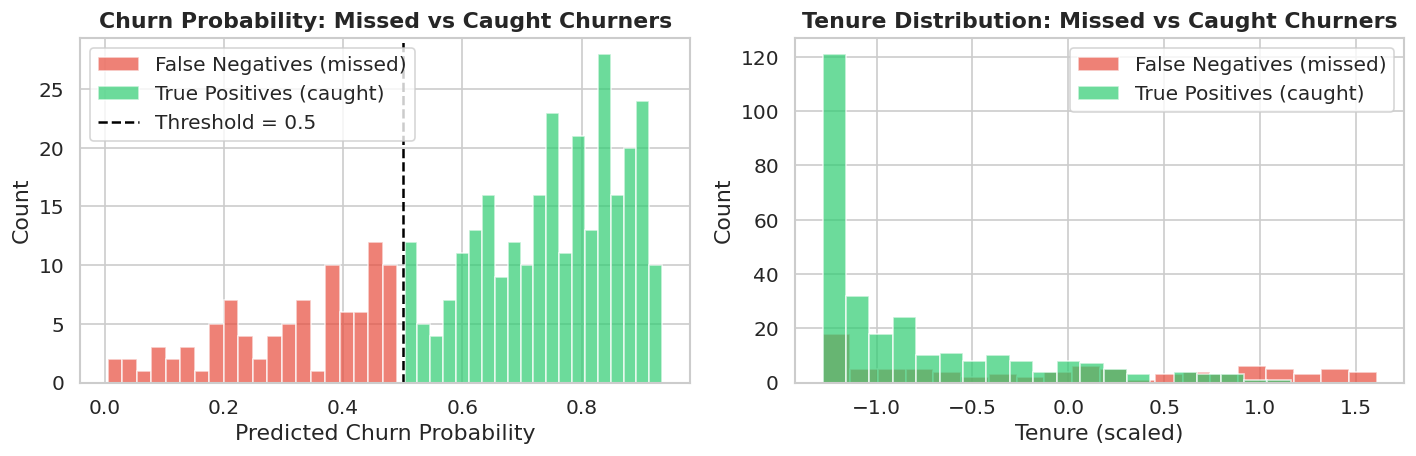

In [ ]:
# ERROR ANALYSIS: FALSE NEGATIVE PROFILING
# identify customers the Random Forest missed (predicted No Churn but actually churned)

# reconstruct test set with original feature values for interpretability
X_test_analysis = X_test.copy()
X_test_analysis['y_true']  = y_test.values
X_test_analysis['y_pred']  = rf_pred
X_test_analysis['y_proba'] = rf_proba

# false negatives: actually churned (1) but predicted as safe (0)
fn_mask = (X_test_analysis['y_true'] == 1) & (X_test_analysis['y_pred'] == 0)
tp_mask = (X_test_analysis['y_true'] == 1) & (X_test_analysis['y_pred'] == 1)

fn_customers = X_test_analysis[fn_mask]
tp_customers = X_test_analysis[tp_mask]

print("FALSE NEGATIVE PROFILE vs CORRECTLY CAUGHT CHURNERS")
print("=" * 60)
print(f"False Negatives (missed churners):     {fn_mask.sum()}")
print(f"True Positives (caught churners):      {tp_mask.sum()}")

print("\nNumerical Features")
for col in ['tenure', 'MonthlyCharges']:
    fn_mean = fn_customers[col].mean()
    tp_mean = tp_customers[col].mean()
    print(f"  {col:20s}  FN mean: {fn_mean:.3f}   TP mean: {tp_mean:.3f}")

print("\nContract Type")
# one-hot encoded: Contract_One year and Contract_Two year
# if both are 0: month-to-month
for col in ['Contract_One year', 'Contract_Two year']:
    fn_rate = fn_customers[col].mean() * 100
    tp_rate = tp_customers[col].mean() * 100
    print(f"  {col:30s}  FN: {fn_rate:.1f}%   TP: {tp_rate:.1f}%")

fn_mtm = ((fn_customers['Contract_One year'] == 0) & (fn_customers['Contract_Two year'] == 0)).mean() * 100
tp_mtm = ((tp_customers['Contract_One year'] == 0) & (tp_customers['Contract_Two year'] == 0)).mean() * 100
print(f"  {'Month-to-month (implicit)':30s}  FN: {fn_mtm:.1f}%   TP: {tp_mtm:.1f}%")

print("\nPredicted Probability Distribution")
print(f"  FN avg churn probability:  {fn_customers['y_proba'].mean():.3f}")
print(f"  TP avg churn probability:  {tp_customers['y_proba'].mean():.3f}")

# visualize probability distribution of FN vs TP
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: churn probability distribution
axes[0].hist(fn_customers['y_proba'], bins=20, alpha=0.7,
             color='#e74c3c', label='False Negatives (missed)', edgecolor='white')
axes[0].hist(tp_customers['y_proba'], bins=20, alpha=0.7,
             color='#2ecc71', label='True Positives (caught)', edgecolor='white')
axes[0].axvline(x=0.5, color='black', linestyle='--', lw=1.5, label='Threshold = 0.5')
axes[0].set_xlabel('Predicted Churn Probability')
axes[0].set_ylabel('Count')
axes[0].set_title('Churn Probability: Missed vs Caught Churners', fontweight='bold')
axes[0].legend()

# right: tenure distribution
axes[1].hist(fn_customers['tenure'], bins=20, alpha=0.7,
             color='#e74c3c', label='False Negatives (missed)', edgecolor='white')
axes[1].hist(tp_customers['tenure'], bins=20, alpha=0.7,
             color='#2ecc71', label='True Positives (caught)', edgecolor='white')
axes[1].set_xlabel('Tenure (scaled)')
axes[1].set_ylabel('Count')
axes[1].set_title('Tenure Distribution: Missed vs Caught Churners', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

The false negative analysis reveals clear patterns in the 93 churners the model missed out of 374 total (25%).

**Contract type** is the most striking difference. Nearly all correctly caught churners (98.9%) were on month-to-month contracts, the highest-risk type the model has learned to flag confidently. Missed churners are disproportionately on longer-term contracts (35.5% one-year, 9.7% two-year), which are atypical churners the model struggles to detect since contract type is its strongest signal.

**Tenure and monthly charges** point in the same direction: missed churners have higher tenure (-0.042 vs -0.854) and lower monthly charges (0.054 vs 0.328) than caught churners. The model associates short tenure and high charges with churn risk - customers who don't fit that profile are harder to flag.

**Predicted probability** confirms these are borderline cases: missed churners average 0.318, just below the 0.5 threshold, while caught churners average 0.754. Lowering the threshold to ~0.35 would recover a meaningful share of these customers.

The model's blind spot is a specific segment: longer-tenured customers on non-month-to-month contracts with moderate charges. These customers may require rule-based triggers, such as a spike in support tickets or a drop in service usage, rather than the probability score alone.

## Conclusions


This project built an end-to-end customer churn prediction pipeline for a telecommunications company, following the full CRISP-DM cycle from business understanding through data preparation, modeling, evaluation, and hyperparameter tuning. We now summarize the key findings across all phases and translate them into actionable business recommendations.

**Model Performance Summary.**

Three binary classifiers were trained and evaluated on the Telco Customer Churn dataset. All three models substantially outperform the random baseline (ROC-AUC = 0.5), confirming that the dataset contains genuine and learnable churn signals.

The **baseline Random Forest** is the recommended final model, achieving the best test set ROC-AUC of 0.8392 and the highest PR-AUC of 0.6434, with a strong balance between precision (0.54) and recall (0.75). It correctly identifies 75% of customers who will churn while keeping false alarms at a manageable level. Hyperparameter tuning via GridSearchCV did not improve test set performance for any model, confirming that the manually chosen baseline configurations already generalized well to the real-world class distribution.

**XGBoost** remains the preferred choice in scenarios where missing a churner is extremely costly, since it achieves the highest recall of 0.84, catching 84% of all actual churners at the cost of more false alarms. **Logistic Regression** is the preferred choice when explainability to non-technical stakeholders is required, as its coefficients provide a transparent and auditable view of what drives churn.

**Key Business Insights.**

The analysis consistently identified the same set of churn drivers across EDA, feature importance, and Logistic Regression coefficients, increasing confidence that these are genuine signals rather than noise.

**Contract type** is the single strongest predictor of churn. Month-to-month customers churn at ~43%, compared to ~11% for one-year and ~3% for two-year contracts. Incentivizing customers to commit to longer contracts, through discounts, loyalty rewards, or bundled benefits, which is likely the highest-impact retention lever available.

**Tenure** is the most important feature in the Random Forest model. Churn risk is highest in the first 12 months and drops significantly after year one. This points to the need for targeted onboarding programs and early-stage engagement campaigns for new customers.

**Monthly charges** are positively correlated with churn. Price-sensitive customers on high-cost plans are at elevated risk. Personalized pricing reviews or mid-contract upgrade offers for high-charge customers could reduce this risk.

**Value-added services** such as OnlineSecurity, TechSupport, and StreamingTV are associated with lower churn. Customers who use more services are more embedded in the ecosystem and less likely to leave. Proactively promoting service bundles to at-risk customers is a direct and measurable retention strategy.

**Electronic check payment** is the payment method most associated with churn, possibly indicating less engaged or less satisfied customers. This segment may benefit from dedicated outreach.

**Limitations and Next Steps.**

Several limitations of this project should be acknowledged. The dataset is a static snapshot, it does not capture how customer behavior evolves over time. A production churn model would benefit from time-series features such as month-over-month usage trends or recent support ticket volume. Additionally, SMOTE generates synthetic samples rather than real customer data, which may introduce slight distributional artifacts into the training set.

Possible extensions for future work include: training a survival analysis model (e.g. Cox Proportional Hazards) to predict not just whether a customer will churn but when; building a cost-sensitive model that explicitly incorporates the financial asymmetry between a missed churner and a false alarm; and deploying the model as a scoring pipeline that ranks all active customers by churn probability on a weekly basis, feeding directly into the CRM retention workflow.